# Stage 2 — Gust control with a thin-airfoil model

**Vamsi Gudipati**

This notebook applies the same method to a two-dimensional airfoil in a vertical gust. The lift follows thin-airfoil theory, the gust changes the effective angle of attack, and a flap is the control. I train a TD3 agent to keep the lift at its target through a fixed gust and random gusts, compare it with the uncontrolled airfoil, and added a training animation, a flight animation and the experiments behind the discussion questions (algorithm choice, observation of the gust, smoothness penalty, flap speed, training-gust strength, drag weighting and a nonlinear lift law).

Cell numbers quoted inside this notebook count the first cell below this header as cell 0.

Portfolio page: https://vamsigudipati.github.io/airfoil-cfd-surrogate-drl.html


# Stage 2 — Deep Reinforcement Learning for Active Control of a 2D Airfoil

In this notebook we apply **deep reinforcement learning (DRL)** to a simplified aerodynamic-control problem.

We consider a 2D airfoil flying at constant freestream velocity $U_\infty$. A vertical gust changes the effective angle of attack and therefore the lift coefficient. The controller acts on a flap and tries to keep the lift close to a prescribed target.

The main chain is

$$
\text{gust}
\;\longrightarrow\;
\alpha_{\mathrm{eff}}
\;\longrightarrow\;
C_L
\;\longrightarrow\;
\text{DRL controller}
\;\longrightarrow\;
\delta_f .
$$

The goal is not to reproduce full CFD. Instead, we build a low-order aerodynamic model that is fast enough to train with PPO, SAC, or TD3.

### Objectives

This notebook sets out to show how to:

- formulate an aerodynamic-control problem as a Markov decision process;
- define observations, actions, and rewards for a continuous-control problem;
- implement the problem as a Gymnasium environment;
- train PPO, SAC, or TD3 with Stable-Baselines3;
- test the trained controller on gusts not used during training;
- understand why a reduced-order model is useful before moving to CFD.

## 1. Install the required libraries

This cell is useful in Google Colab. If the packages are already installed, it can be skipped.

In [1]:
%pip -q install "stable-baselines3[extra]" gymnasium

Note: you may need to restart the kernel to use updated packages.


## 2. Imports and reproducibility

In [2]:
import numpy as np
import matplotlib.pyplot as plt

import gymnasium as gym
from gymnasium import spaces

from stable_baselines3 import PPO, SAC, TD3
from stable_baselines3.common.monitor import Monitor
from stable_baselines3.common.env_checker import check_env
from stable_baselines3.common.noise import NormalActionNoise

SEED = 7
np.random.seed(SEED)

## 3. Reduced aerodynamic model

For moderate angles of attack, thin-airfoil theory gives

$$
C_{L,\mathrm{qs}} = 2\pi \alpha_{\mathrm{eff}},
$$

where the angle is measured in radians.

The effective angle of attack is modeled as

$$
\alpha_{\mathrm{eff}}
=
\alpha_0
+
\alpha_{\mathrm{gust}}
+
k_f\delta_f,
$$

where

- $\alpha_0$ is the geometric angle of attack,
- $\alpha_{\mathrm{gust}}$ is produced by the incoming gust,
- $\delta_f$ is the flap deflection,
- $k_f$ measures the flap effectiveness.

A purely quasi-steady model would react instantaneously. To introduce aerodynamic memory, we instead use

$$
\tau_L \frac{dC_L}{dt}
=
C_{L,\mathrm{qs}}-C_L.
$$

The flap also has its own first-order dynamics:

$$
\tau_f \frac{d\delta_f}{dt}
=
\delta_{f,\mathrm{cmd}}-\delta_f.
$$

The agent therefore commands the flap angle, but the physical flap cannot jump instantaneously.

For the drag we use the simple polar

$$
C_D = C_{D0}+k_D C_L^2+k_\delta \delta_f^2.
$$

This is intentionally a reduced model. Later it can be replaced by a surrogate or CFD solver without changing the DRL formulation.

## 4. A one-minus-cosine gust

We use a smooth vertical gust

$$
w_g(t)=
\frac{W_0}{2}
\left[
1-\cos\left(
2\pi\frac{t-t_0}{T_g}
\right)
\right]
$$

during the gust interval and zero elsewhere.

The corresponding change in angle of attack is approximated by

$$
\alpha_{\mathrm{gust}}
=
\tan^{-1}\left(\frac{w_g}{U_\infty}\right).
$$

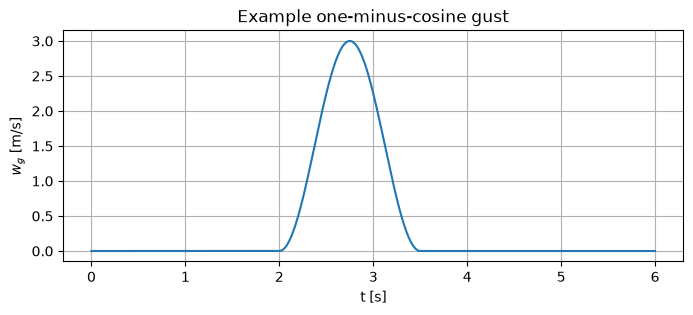

In [3]:
def one_minus_cosine_gust(t, t0, duration, amplitude):
    if t < t0 or t > t0 + duration:
        return 0.0

    xi = (t - t0) / duration
    return 0.5 * amplitude * (1.0 - np.cos(2.0 * np.pi * xi))


# Example gust
t_demo = np.linspace(0.0, 6.0, 500)
w_demo = np.array([
    one_minus_cosine_gust(t, t0=2.0, duration=1.5, amplitude=3.0)
    for t in t_demo
])

plt.figure(figsize=(8, 3))
plt.plot(t_demo, w_demo)
plt.xlabel("t [s]")
plt.ylabel(r"$w_g$ [m/s]")
plt.title("Example one-minus-cosine gust")
plt.grid(True)
plt.show()

## 5. Optional nonlinear lift curve

A linear lift law is useful for learning the formulation, but it predicts unlimited lift as the angle of attack increases.

For a slightly more realistic extension we introduce an optional smooth saturation model. The notebook uses the **linear model by default**, while the nonlinear model can be activated later by changing one variable.

This is still not a full dynamic-stall model. Its only purpose is to introduce aerodynamic nonlinearity.

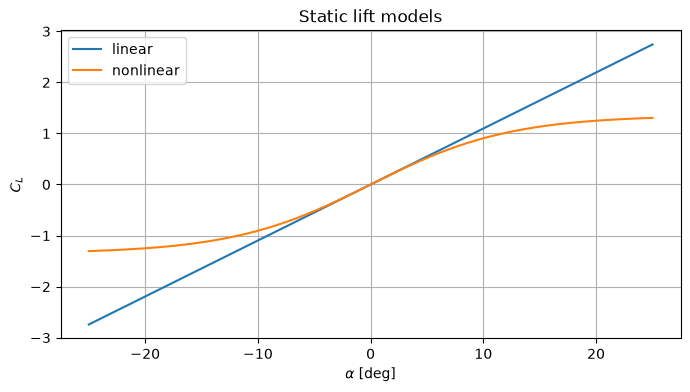

In [4]:
def static_lift_coefficient(alpha_rad, model="linear"):
    if model == "linear":
        return 2.0 * np.pi * alpha_rad

    if model == "nonlinear":
        # Linear behavior at small alpha with smooth saturation at large alpha.
        cl_linear = 2.0 * np.pi * alpha_rad
        cl_max = 1.35
        return cl_max * np.tanh(cl_linear / cl_max)

    raise ValueError("model must be 'linear' or 'nonlinear'")


alpha_deg = np.linspace(-25.0, 25.0, 300)
alpha_rad = np.deg2rad(alpha_deg)

plt.figure(figsize=(8, 4))
plt.plot(alpha_deg, static_lift_coefficient(alpha_rad, "linear"), label="linear")
plt.plot(alpha_deg, static_lift_coefficient(alpha_rad, "nonlinear"), label="nonlinear")
plt.xlabel(r"$\alpha$ [deg]")
plt.ylabel(r"$C_L$")
plt.title("Static lift models")
plt.legend()
plt.grid(True)
plt.show()

## 6. Gymnasium environment

We now turn the aerodynamic problem into a reinforcement-learning environment.

### Observation

The agent observes

$$
s_t =
\begin{bmatrix}
C_L,\;
C_{L,\mathrm{target}},\;
\alpha_{\mathrm{gust}},\;
\delta_f
\end{bmatrix}.
$$

The variables are scaled to values of order one before they are passed to the neural network.

### Action

The action is continuous:

$$
a_t\in[-1,1].
$$

It is mapped to a commanded flap angle

$$
\delta_{f,\mathrm{cmd}}
=
a_t\,\delta_{f,\max}.
$$

### Reward

We use

$$
r_t =
-(C_L-C_{L,\mathrm{target}})^2
-\lambda_a a_t^2
-\lambda_{\Delta a}(a_t-a_{t-1})^2
-\lambda_D C_D.
$$

Thus the controller is rewarded for accurate lift tracking but penalized for excessive or abrupt control action and, weakly, for drag.

In [5]:
class AirfoilGymEnv(gym.Env):
    metadata = {"render_modes": []}

    def __init__(
        self,
        dt=0.05,
        horizon=120,
        U_inf=30.0,
        alpha0_deg=5.0,
        cl_target=0.55,
        max_flap_deg=20.0,
        flap_effectiveness=0.55,
        tau_lift=0.18,
        tau_flap=0.10,
        cd0=0.012,
        induced_drag_factor=0.025,
        flap_drag_factor=0.08,
        lift_model="linear",
        random_gust=True,
        gust_amplitude_range=(-3.0, 3.0),
        gust_duration_range=(0.8, 1.8),
        gust_start_range=(1.0, 3.0),
        effort_weight=0.015,
        smoothness_weight=0.020,
        drag_weight=0.020,
    ):
        super().__init__()

        self.dt = dt
        self.horizon = horizon
        self.U_inf = U_inf
        self.alpha0_deg = alpha0_deg
        self.cl_target = cl_target
        self.max_flap_deg = max_flap_deg
        self.flap_effectiveness = flap_effectiveness
        self.tau_lift = tau_lift
        self.tau_flap = tau_flap

        self.cd0 = cd0
        self.induced_drag_factor = induced_drag_factor
        self.flap_drag_factor = flap_drag_factor
        self.lift_model = lift_model

        self.random_gust = random_gust
        self.gust_amplitude_range = gust_amplitude_range
        self.gust_duration_range = gust_duration_range
        self.gust_start_range = gust_start_range

        self.effort_weight = effort_weight
        self.smoothness_weight = smoothness_weight
        self.drag_weight = drag_weight

        self.action_space = spaces.Box(
            low=-1.0,
            high=1.0,
            shape=(1,),
            dtype=np.float32,
        )

        # The observations are scaled and clipped.
        self.observation_space = spaces.Box(
            low=np.array([-2.0, -2.0, -2.0, -1.5], dtype=np.float32),
            high=np.array([ 2.0,  2.0,  2.0,  1.5], dtype=np.float32),
            dtype=np.float32,
        )

        self.reset()

    def _gust_velocity(self, t):
        return one_minus_cosine_gust(
            t,
            self.gust_start,
            self.gust_duration,
            self.gust_amplitude,
        )

    def _gust_angle_deg(self, t):
        w_g = self._gust_velocity(t)
        return np.rad2deg(np.arctan2(w_g, self.U_inf))

    def _aero(self, gust_angle_deg):
        alpha_eff_deg = (
            self.alpha0_deg
            + gust_angle_deg
            + self.flap_effectiveness * self.flap_deg
        )
        alpha_eff_rad = np.deg2rad(alpha_eff_deg)

        cl_qs = static_lift_coefficient(alpha_eff_rad, self.lift_model)

        flap_rad = np.deg2rad(self.flap_deg)
        cd = (
            self.cd0
            + self.induced_drag_factor * self.cl**2
            + self.flap_drag_factor * flap_rad**2
        )

        return cl_qs, cd, alpha_eff_deg

    def _get_obs(self):
        gust_angle_deg = self._gust_angle_deg(self.t)

        obs = np.array([
            self.cl / 1.5,
            self.cl_target / 1.5,
            gust_angle_deg / 10.0,
            self.flap_deg / self.max_flap_deg,
        ], dtype=np.float32)

        return np.clip(
            obs,
            self.observation_space.low,
            self.observation_space.high,
        )

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)

        self.step_count = 0
        self.t = 0.0
        self.prev_action = 0.0
        self.flap_deg = 0.0

        if self.random_gust:
            self.gust_amplitude = self.np_random.uniform(*self.gust_amplitude_range)
            self.gust_duration = self.np_random.uniform(*self.gust_duration_range)
            self.gust_start = self.np_random.uniform(*self.gust_start_range)
        else:
            self.gust_amplitude = 2.5
            self.gust_duration = 1.3
            self.gust_start = 2.0

        # Initialize the lift close to its zero-gust equilibrium.
        alpha_initial = np.deg2rad(self.alpha0_deg)
        self.cl = float(static_lift_coefficient(alpha_initial, self.lift_model))

        return self._get_obs(), {}

    def step(self, action):
        action = np.asarray(action, dtype=np.float32).reshape(-1)
        action_value = float(np.clip(action[0], -1.0, 1.0))

        flap_command_deg = action_value * self.max_flap_deg

        # First-order flap dynamics.
        self.flap_deg += (
            self.dt / self.tau_flap
        ) * (flap_command_deg - self.flap_deg)

        gust_angle_deg = self._gust_angle_deg(self.t)
        cl_qs, cd, alpha_eff_deg = self._aero(gust_angle_deg)

        # First-order unsteady lift dynamics.
        self.cl += (
            self.dt / self.tau_lift
        ) * (cl_qs - self.cl)

        tracking_error = self.cl - self.cl_target
        delta_action = action_value - self.prev_action

        reward = (
            -tracking_error**2
            -self.effort_weight * action_value**2
            -self.smoothness_weight * delta_action**2
            -self.drag_weight * cd
        )

        self.prev_action = action_value
        self.step_count += 1
        self.t = self.step_count * self.dt

        terminated = False
        truncated = self.step_count >= self.horizon

        info = {
            "time": self.t,
            "cl": self.cl,
            "cl_target": self.cl_target,
            "cd": cd,
            "flap_deg": self.flap_deg,
            "flap_command_deg": flap_command_deg,
            "gust_velocity": self._gust_velocity(self.t),
            "gust_angle_deg": self._gust_angle_deg(self.t),
            "alpha_eff_deg": alpha_eff_deg,
            "tracking_error": tracking_error,
        }

        return self._get_obs(), float(reward), terminated, truncated, info

## 7. Check the environment

Stable-Baselines3 provides a useful checker for custom Gymnasium environments.

In [6]:
test_env = AirfoilGymEnv()
check_env(test_env, warn=True)
print("Environment check passed.")

Environment check passed.


## 8. Inspect one episode with random actions

Before training any neural network, it is important to verify that the environment behaves sensibly.

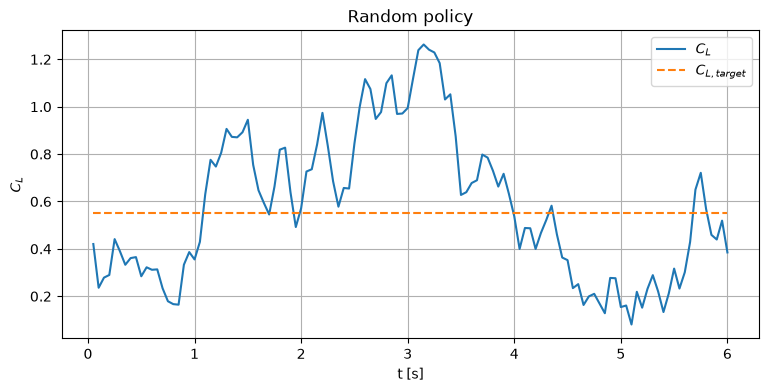

In [7]:
def run_episode(env, model=None, seed=0):
    obs, _ = env.reset(seed=seed)

    data = {
        "time": [],
        "cl": [],
        "cl_target": [],
        "cd": [],
        "flap_deg": [],
        "gust_velocity": [],
        "gust_angle_deg": [],
        "reward": [],
    }

    terminated = truncated = False

    while not (terminated or truncated):
        if model is None:
            action = env.action_space.sample()
        else:
            action, _ = model.predict(obs, deterministic=True)

        obs, reward, terminated, truncated, info = env.step(action)

        data["time"].append(info["time"])
        data["cl"].append(info["cl"])
        data["cl_target"].append(info["cl_target"])
        data["cd"].append(info["cd"])
        data["flap_deg"].append(info["flap_deg"])
        data["gust_velocity"].append(info["gust_velocity"])
        data["gust_angle_deg"].append(info["gust_angle_deg"])
        data["reward"].append(reward)

    return {key: np.asarray(value) for key, value in data.items()}


random_env = AirfoilGymEnv(random_gust=False)
random_episode = run_episode(random_env, model=None, seed=SEED)

plt.figure(figsize=(9, 4))
plt.plot(random_episode["time"], random_episode["cl"], label=r"$C_L$")
plt.plot(
    random_episode["time"],
    random_episode["cl_target"],
    "--",
    label=r"$C_{L,target}$",
)
plt.xlabel("t [s]")
plt.ylabel(r"$C_L$")
plt.title("Random policy")
plt.legend()
plt.grid(True)
plt.show()

## 9. Select the DRL algorithm

The environment has a **continuous action space**, so PPO, SAC, and TD3 are all possible choices.

Change only

```python
MODEL = "PPO"
```

to switch algorithms.

For a classroom demonstration, PPO is a good starting point. SAC and TD3 are useful comparisons because they are off-policy algorithms designed for continuous control.

In [8]:
MODEL = "TD3"       # "PPO", "SAC", or "TD3"
TOTAL_TIMESTEPS = 50_000

training_env = Monitor(
    AirfoilGymEnv(
        lift_model="linear",
        random_gust=True,
    )
)

if MODEL == "PPO":
    model = PPO(
        policy="MlpPolicy",
        env=training_env,
        learning_rate=3e-4,
        n_steps=1024,
        batch_size=64,
        gamma=0.99,
        verbose=1,
        seed=SEED,
    )

elif MODEL == "SAC":
    model = SAC(
        policy="MlpPolicy",
        env=training_env,
        learning_rate=3e-4,
        buffer_size=100_000,
        batch_size=256,
        gamma=0.99,
        verbose=1,
        seed=SEED,
    )

elif MODEL == "TD3":
    n_actions = training_env.action_space.shape[-1]

    action_noise = NormalActionNoise(
        mean=np.zeros(n_actions),
        sigma=0.10 * np.ones(n_actions),
    )

    model = TD3(
        policy="MlpPolicy",
        env=training_env,
        learning_rate=1e-3,
        buffer_size=100_000,
        batch_size=256,
        gamma=0.99,
        action_noise=action_noise,
        verbose=1,
        seed=SEED,
    )

else:
    raise ValueError("MODEL must be 'PPO', 'SAC', or 'TD3'")

print(f"Selected model: {MODEL}")

Using cpu device
Wrapping the env in a DummyVecEnv.


Selected model: TD3


## 10. Train the agent

Fifty thousand time steps are usually enough to observe clear learning in this simplified environment. For a more careful comparison between algorithms, increase the training budget and repeat the experiment with several random seeds.

## Animation step 1 — record snapshots while the agent learns

The pattern: **train once and save snapshots**. Every `SNAPSHOT_EVERY` steps the current policy flies the fixed evaluation gust once (deterministic actions), and the episode is stored with the training returns logged so far. After training, the agent itself is saved to `trained_models/`.

In [9]:
# ================================================================
# ANIMATION STEP 1 — SNAPSHOT CALLBACK
# Every SNAPSHOT_EVERY steps the current policy flies the fixed evaluation gust
# (random_gust=False) once, deterministically; the episode is stored.
# ================================================================
import pickle
from pathlib import Path
from stable_baselines3.common.callbacks import BaseCallback

ANIM_DIR = Path("../animations"); ANIM_DIR.mkdir(exist_ok=True)
MODEL_DIR = Path("../models/02_airfoil_gust_control_thin_airfoil"); MODEL_DIR.mkdir(exist_ok=True)
SNAPSHOT_EVERY = 1_000
TRACE_KEYS = ["time", "cl", "cl_target", "cd", "flap_deg", "gust_velocity", "gust_angle_deg", "alpha_eff_deg"]


def fixed_gust_rollout(policy, env):
    obs, _ = env.reset(seed=0)
    out = {k: [] for k in TRACE_KEYS + ["reward"]}
    done = False
    while not done:
        action, _ = policy.predict(obs, deterministic=True)
        obs, reward, terminated, truncated, info = env.step(action)
        done = terminated or truncated
        for k in TRACE_KEYS:
            out[k].append(info[k])
        out["reward"].append(reward)
    return {k: np.asarray(v) for k, v in out.items()}


class AirfoilSnapshotCallback(BaseCallback):
    def __init__(self, monitor, every, env_factory):
        super().__init__()
        self.monitor, self.every, self.env_factory = monitor, every, env_factory
        self.snapshots = []

    def _take(self):
        trace = fixed_gust_rollout(self.model, self.env_factory())
        self.snapshots.append({
            "timestep": int(self.num_timesteps), "trace": trace,
            "episode_rewards": list(self.monitor.get_episode_rewards()),
            "episode_lengths": list(self.monitor.get_episode_lengths()),
        })

    def _on_training_start(self):
        self._take()

    def _on_step(self):
        if self.num_timesteps % self.every == 0:
            self._take()
        return True


snapshot_callback = AirfoilSnapshotCallback(training_env, SNAPSHOT_EVERY, lambda: AirfoilGymEnv(lift_model="linear", random_gust=False))
print(f"Snapshot every {SNAPSHOT_EVERY:,} steps -> {TOTAL_TIMESTEPS // SNAPSHOT_EVERY + 1} frames")

Snapshot every 1,000 steps -> 51 frames


In [10]:
model.learn(total_timesteps=TOTAL_TIMESTEPS, callback=snapshot_callback)  # callback added for the animation

---------------------------------
| rollout/           |          |
|    ep_len_mean     | 120      |
|    ep_rew_mean     | -2.43    |
| time/              |          |
|    episodes        | 4        |
|    fps             | 254      |
|    time_elapsed    | 1        |
|    total_timesteps | 480      |
| train/             |          |
|    actor_loss      | 0.104    |
|    critic_loss     | 8.02e-05 |
|    learning_rate   | 0.001    |
|    n_updates       | 379      |
---------------------------------


---------------------------------
| rollout/           |          |
|    ep_len_mean     | 120      |
|    ep_rew_mean     | -1.34    |
| time/              |          |
|    episodes        | 8        |
|    fps             | 234      |
|    time_elapsed    | 4        |
|    total_timesteps | 960      |
| train/             |          |
|    actor_loss      | 0.101    |
|    critic_loss     | 6.88e-05 |
|    learning_rate   | 0.001    |
|    n_updates       | 859      |
---------------------------------


---------------------------------
| rollout/           |          |
|    ep_len_mean     | 120      |
|    ep_rew_mean     | -0.989   |
| time/              |          |
|    episodes        | 12       |
|    fps             | 223      |
|    time_elapsed    | 6        |
|    total_timesteps | 1440     |
| train/             |          |
|    actor_loss      | 0.105    |
|    critic_loss     | 0.000135 |
|    learning_rate   | 0.001    |
|    n_updates       | 1339     |
---------------------------------


---------------------------------
| rollout/           |          |
|    ep_len_mean     | 120      |
|    ep_rew_mean     | -0.8     |
| time/              |          |
|    episodes        | 16       |
|    fps             | 222      |
|    time_elapsed    | 8        |
|    total_timesteps | 1920     |
| train/             |          |
|    actor_loss      | 0.108    |
|    critic_loss     | 0.000144 |
|    learning_rate   | 0.001    |
|    n_updates       | 1819     |
---------------------------------


---------------------------------
| rollout/           |          |
|    ep_len_mean     | 120      |
|    ep_rew_mean     | -0.683   |
| time/              |          |
|    episodes        | 20       |
|    fps             | 219      |
|    time_elapsed    | 10       |
|    total_timesteps | 2400     |
| train/             |          |
|    actor_loss      | 0.113    |
|    critic_loss     | 0.000141 |
|    learning_rate   | 0.001    |
|    n_updates       | 2299     |
---------------------------------


...

---------------------------------
| rollout/           |          |
|    ep_len_mean     | 120      |
|    ep_rew_mean     | -0.25    |
| time/              |          |
|    episodes        | 400      |
|    fps             | 213      |
|    time_elapsed    | 224      |
|    total_timesteps | 48000    |
| train/             |          |
|    actor_loss      | 0.423    |
|    critic_loss     | 0.000154 |
|    learning_rate   | 0.001    |
|    n_updates       | 47899    |
---------------------------------


---------------------------------
| rollout/           |          |
|    ep_len_mean     | 120      |
|    ep_rew_mean     | -0.251   |
| time/              |          |
|    episodes        | 404      |
|    fps             | 213      |
|    time_elapsed    | 227      |
|    total_timesteps | 48480    |
| train/             |          |
|    actor_loss      | 0.431    |
|    critic_loss     | 0.000158 |
|    learning_rate   | 0.001    |
|    n_updates       | 48379    |
---------------------------------


---------------------------------
| rollout/           |          |
|    ep_len_mean     | 120      |
|    ep_rew_mean     | -0.25    |
| time/              |          |
|    episodes        | 408      |
|    fps             | 213      |
|    time_elapsed    | 229      |
|    total_timesteps | 48960    |
| train/             |          |
|    actor_loss      | 0.431    |
|    critic_loss     | 0.000107 |
|    learning_rate   | 0.001    |
|    n_updates       | 48859    |
---------------------------------


---------------------------------
| rollout/           |          |
|    ep_len_mean     | 120      |
|    ep_rew_mean     | -0.251   |
| time/              |          |
|    episodes        | 412      |
|    fps             | 213      |
|    time_elapsed    | 231      |
|    total_timesteps | 49440    |
| train/             |          |
|    actor_loss      | 0.431    |
|    critic_loss     | 0.000114 |
|    learning_rate   | 0.001    |
|    n_updates       | 49339    |
---------------------------------


---------------------------------
| rollout/           |          |
|    ep_len_mean     | 120      |
|    ep_rew_mean     | -0.249   |
| time/              |          |
|    episodes        | 416      |
|    fps             | 213      |
|    time_elapsed    | 233      |
|    total_timesteps | 49920    |
| train/             |          |
|    actor_loss      | 0.43     |
|    critic_loss     | 0.000124 |
|    learning_rate   | 0.001    |
|    n_updates       | 49819    |
---------------------------------


In [11]:
# ================================================================
# ANIMATION STEP 1b + MODEL SAVE
# ================================================================
FINAL_MODEL_PATH = MODEL_DIR / f"airfoil_0d_{MODEL.lower()}_final"
model.save(FINAL_MODEL_PATH)
print("Saved trained agent:", str(FINAL_MODEL_PATH) + ".zip")

SNAPSHOT_FILE = ANIM_DIR / "02_airfoil_0d_training_snapshots.pkl"
pickle.dump({"snapshots": snapshot_callback.snapshots, "algo": MODEL,
             "total_timesteps": TOTAL_TIMESTEPS}, open(SNAPSHOT_FILE, "wb"))
print(f"{len(snapshot_callback.snapshots)} snapshots saved to {SNAPSHOT_FILE}")

Saved trained agent: ../models/02_airfoil_gust_control_thin_airfoil/airfoil_0d_td3_final.zip
51 snapshots saved to ../animations/02_airfoil_0d_training_snapshots.pkl


## 11. Evaluate the trained controller on a fixed gust

Training uses randomized gusts. We now evaluate the learned policy on a deterministic gust so that different controllers can be compared fairly.

In [12]:
evaluation_env = AirfoilGymEnv(
    lift_model="linear",
    random_gust=False,
)

controlled = run_episode(
    evaluation_env,
    model=model,
    seed=123,
)

uncontrolled_env = AirfoilGymEnv(
    lift_model="linear",
    random_gust=False,
)

class ZeroPolicy:
    def predict(self, obs, deterministic=True):
        return np.array([0.0], dtype=np.float32), None

uncontrolled = run_episode(
    uncontrolled_env,
    model=ZeroPolicy(),
    seed=123,
)

## 12. Visual comparison

The important questions are:

1. How much does the gust disturb the lift?
2. Does the controller reduce the lift error?
3. How large are the flap motions?
4. Does the controller react smoothly?

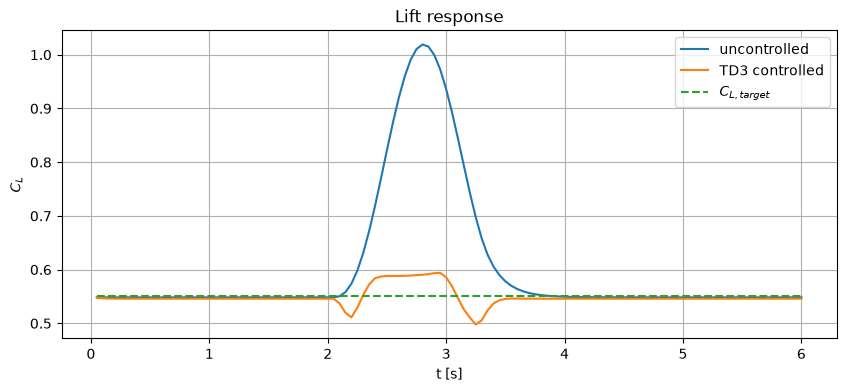

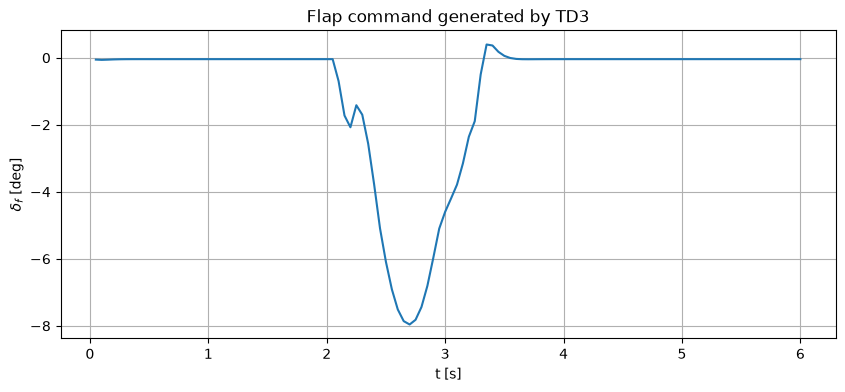

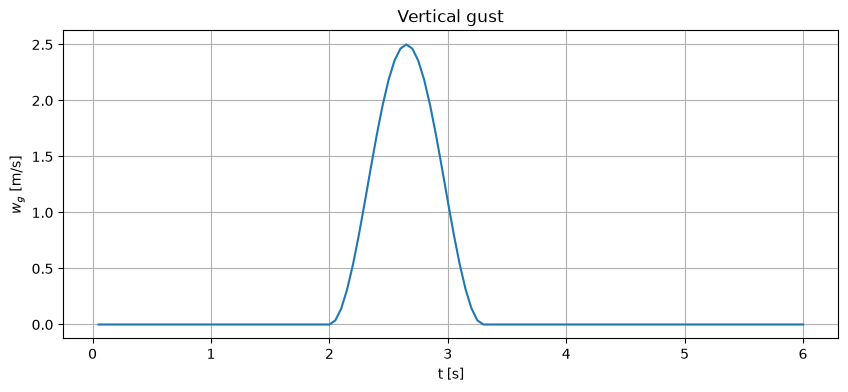

In [13]:
plt.figure(figsize=(10, 4))
plt.plot(
    uncontrolled["time"],
    uncontrolled["cl"],
    label="uncontrolled",
)
plt.plot(
    controlled["time"],
    controlled["cl"],
    label=f"{MODEL} controlled",
)
plt.plot(
    controlled["time"],
    controlled["cl_target"],
    "--",
    label=r"$C_{L,target}$",
)
plt.xlabel("t [s]")
plt.ylabel(r"$C_L$")
plt.title("Lift response")
plt.legend()
plt.grid(True)
plt.show()


plt.figure(figsize=(10, 4))
plt.plot(controlled["time"], controlled["flap_deg"])
plt.xlabel("t [s]")
plt.ylabel(r"$\delta_f$ [deg]")
plt.title(f"Flap command generated by {MODEL}")
plt.grid(True)
plt.show()


plt.figure(figsize=(10, 4))
plt.plot(controlled["time"], controlled["gust_velocity"])
plt.xlabel("t [s]")
plt.ylabel(r"$w_g$ [m/s]")
plt.title("Vertical gust")
plt.grid(True)
plt.show()

## 13. Quantitative metrics

A controller should not be judged only from a figure.

We compute the root-mean-square lift error

$$
\mathrm{RMSE}(C_L)
=
\sqrt{
\frac{1}{N}
\sum_{n=1}^{N}
\left(
C_L^{(n)}-C_{L,\mathrm{target}}
\right)^2
}
$$

and the mean absolute flap angle.

In [14]:
def episode_metrics(data):
    error = data["cl"] - data["cl_target"]

    return {
        "CL_RMSE": np.sqrt(np.mean(error**2)),
        "mean_abs_flap_deg": np.mean(np.abs(data["flap_deg"])),
        "max_abs_flap_deg": np.max(np.abs(data["flap_deg"])),
        "mean_CD": np.mean(data["cd"]),
        "episode_return": np.sum(data["reward"]),
    }


metrics_uncontrolled = episode_metrics(uncontrolled)
metrics_controlled = episode_metrics(controlled)

print("Uncontrolled")
for key, value in metrics_uncontrolled.items():
    print(f"  {key:20s}: {value:.5f}")

print(f"\n{MODEL} controlled")
for key, value in metrics_controlled.items():
    print(f"  {key:20s}: {value:.5f}")

Uncontrolled
  CL_RMSE             : 0.13852
  mean_abs_flap_deg   : 0.00000
  max_abs_flap_deg    : 0.00000
  mean_CD             : 0.02155
  episode_return      : -2.35426

TD3 controlled
  CL_RMSE             : 0.01663
  mean_abs_flap_deg   : 0.94856
  max_abs_flap_deg    : 7.96027
  mean_CD             : 0.01966
  episode_return      : -0.10624


## 14. Test on unseen gusts

A useful DRL controller should generalize beyond one prescribed disturbance.

The next cell evaluates the same trained network on several gust amplitudes and durations that were not fixed during training.

In [15]:
def evaluate_on_gust(
    model,
    amplitude,
    duration,
    start=2.0,
    seed=0,
):
    env = AirfoilGymEnv(
        lift_model="linear",
        random_gust=False,
    )

    obs, _ = env.reset(seed=seed)
    env.gust_amplitude = amplitude
    env.gust_duration = duration
    env.gust_start = start

    data = {
        "time": [],
        "cl": [],
        "cl_target": [],
        "cd": [],
        "flap_deg": [],
        "gust_velocity": [],
        "gust_angle_deg": [],
        "reward": [],
    }

    terminated = truncated = False

    while not (terminated or truncated):
        action, _ = model.predict(obs, deterministic=True)
        obs, reward, terminated, truncated, info = env.step(action)

        data["time"].append(info["time"])
        data["cl"].append(info["cl"])
        data["cl_target"].append(info["cl_target"])
        data["cd"].append(info["cd"])
        data["flap_deg"].append(info["flap_deg"])
        data["gust_velocity"].append(info["gust_velocity"])
        data["gust_angle_deg"].append(info["gust_angle_deg"])
        data["reward"].append(reward)

    return {key: np.asarray(value) for key, value in data.items()}


test_cases = [
    (-3.5, 1.0),
    (-2.0, 1.7),
    ( 2.0, 1.1),
    ( 3.5, 1.6),
]

for amplitude, duration in test_cases:
    result = evaluate_on_gust(
        model,
        amplitude=amplitude,
        duration=duration,
        start=2.0,
    )

    metrics = episode_metrics(result)

    print(
        f"W0={amplitude:+.1f} m/s, "
        f"Tg={duration:.1f} s  ->  "
        f"CL_RMSE={metrics['CL_RMSE']:.4f}, "
        f"max|flap|={metrics['max_abs_flap_deg']:.2f} deg"
    )

W0=-3.5 m/s, Tg=1.0 s  ->  CL_RMSE=0.0128, max|flap|=12.05 deg
W0=-2.0 m/s, Tg=1.7 s  ->  CL_RMSE=0.0202, max|flap|=6.33 deg
W0=+2.0 m/s, Tg=1.1 s  ->  CL_RMSE=0.0154, max|flap|=6.17 deg


W0=+3.5 m/s, Tg=1.6 s  ->  CL_RMSE=0.0176, max|flap|=11.58 deg


## 15. Optional extension: nonlinear aerodynamics

The same controller architecture can be trained using

```python
lift_model="nonlinear"
```

instead of the linear thin-airfoil approximation.

Now the mapping between angle of attack and lift is nonlinear, so large flap deflections do not produce a proportional increase in lift.

This is a useful intermediate step before replacing the reduced model by data from XFOIL, a CFD surrogate, or OpenFOAM.

In [16]:
nonlinear_env = AirfoilGymEnv(
    lift_model="nonlinear",
    random_gust=False,
)

obs, _ = nonlinear_env.reset(seed=SEED)

print("Nonlinear environment ready.")
print("Initial observation:", obs)

Nonlinear environment ready.
Initial observation: [0.34668395 0.36666667 0.         0.        ]


# 15b. Animation — the controller learning to reject the gust

Following the same pattern (train and save snapshots → preview the final frame → render), the dashboard shows, for every snapshot of the policy during training, one flight through the fixed evaluation gust:

- **Top-left — lift response**: $C_L(t)$ of the current policy, the uncontrolled response and the target.
- **Top-right — training curve**: the return of every training episode logged so far, with a moving average; the dotted line marks the snapshot.
- **Bottom-left — flap deflection** $\delta_f(t)$ chosen by the current policy.
- **Bottom-right — angles**: the gust-induced angle and the resulting effective angle of attack $\alpha_{\mathrm{eff}}$. 

A second animation then shows the **airfoil itself** flying through the gust, uncontrolled and controlled.

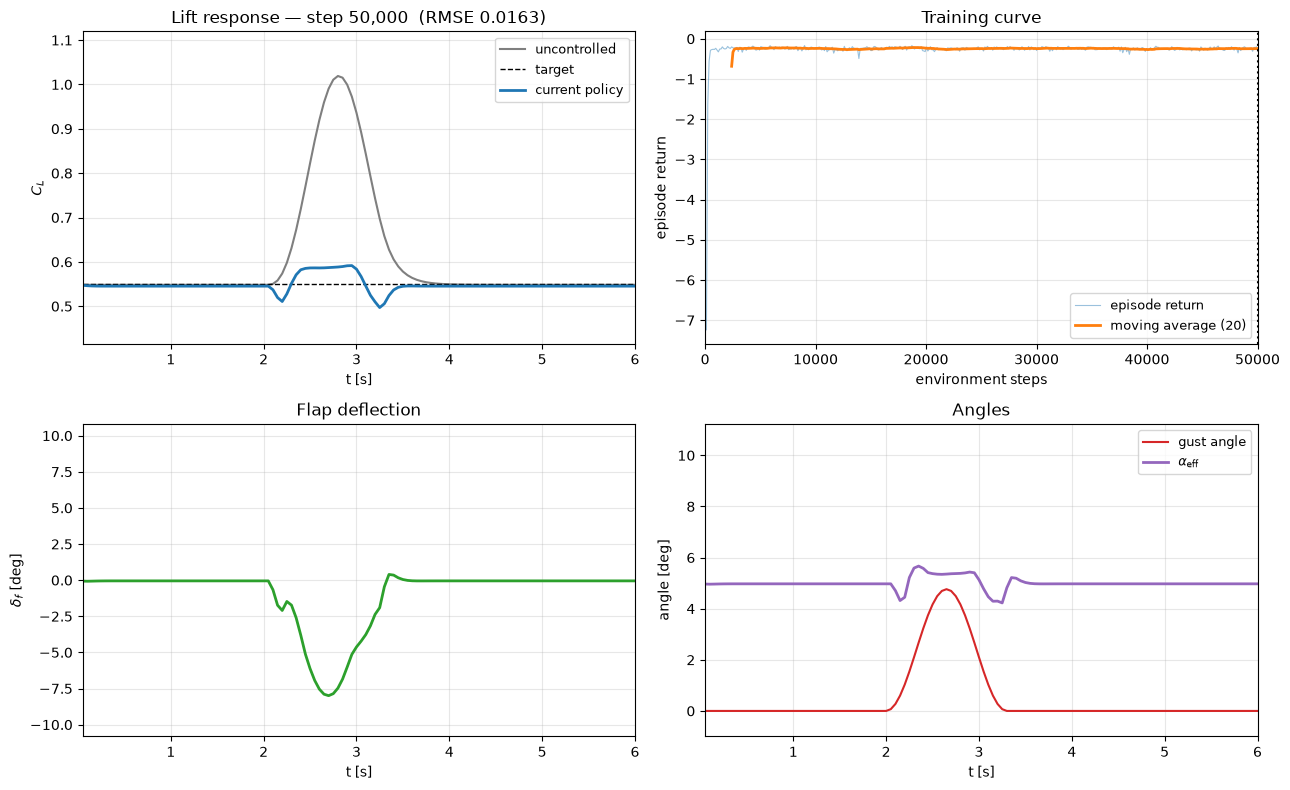

In [17]:
# ================================================================
# ANIMATION CELL 2 — PREVIEW THE FINAL FRAME
# ================================================================
import pickle
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display

anim_data = pickle.load(open(ANIM_DIR / "02_airfoil_0d_training_snapshots.pkl", "rb"))
snaps = anim_data["snapshots"]
unc = uncontrolled
final_rewards = np.asarray(snaps[-1]["episode_rewards"])
cl_all = np.concatenate([s["trace"]["cl"] for s in snaps] + [unc["cl"]])
flap_all = np.concatenate([s["trace"]["flap_deg"] for s in snaps])
alpha_all = np.concatenate([s["trace"]["alpha_eff_deg"] for s in snaps] + [s["trace"]["gust_angle_deg"] for s in snaps])


def build_airfoil_dashboard():
    fig, axes = plt.subplots(2, 2, figsize=(13, 8))
    ax_cl, ax_r, ax_f, ax_a = axes[0, 0], axes[0, 1], axes[1, 0], axes[1, 1]
    t = snaps[0]["trace"]["time"]

    ax_cl.plot(unc["time"], unc["cl"], color="tab:gray", lw=1.5, label="uncontrolled")
    ax_cl.plot(t, snaps[0]["trace"]["cl_target"], "k--", lw=1, label="target")
    cl_line, = ax_cl.plot([], [], color="tab:blue", lw=2, label="current policy")
    ax_cl.set_xlim(t[0], t[-1]); ax_cl.set_ylim(cl_all.min() - 0.05, cl_all.max() + 0.05)
    ax_cl.set_xlabel("t [s]"); ax_cl.set_ylabel(r"$C_L$"); ax_cl.grid(True, alpha=0.3); ax_cl.legend(fontsize=9)
    title_cl = ax_cl.set_title("")

    ax_r.set_xlim(0, anim_data["total_timesteps"])
    pad = 0.05 * (final_rewards.max() - final_rewards.min() + 1e-9)
    ax_r.set_ylim(final_rewards.min() - pad, final_rewards.max() + pad)
    ax_r.set_xlabel("environment steps"); ax_r.set_ylabel("episode return"); ax_r.set_title("Training curve")
    ax_r.grid(True, alpha=0.3)
    rew_line, = ax_r.plot([], [], lw=0.8, alpha=0.45, label="episode return")
    avg_line, = ax_r.plot([], [], lw=2.0, label="moving average (20)")
    vline = ax_r.axvline(0, color="k", ls=":")
    ax_r.legend(loc="lower right", fontsize=9)

    flap_line, = ax_f.plot([], [], color="tab:green", lw=2)
    lim = max(1.0, np.abs(flap_all).max() * 1.1)
    ax_f.set_xlim(t[0], t[-1]); ax_f.set_ylim(-lim, lim)
    ax_f.set_xlabel("t [s]"); ax_f.set_ylabel(r"$\delta_f$ [deg]"); ax_f.set_title("Flap deflection")
    ax_f.grid(True, alpha=0.3)

    gust_line, = ax_a.plot([], [], color="tab:red", lw=1.5, label="gust angle")
    alpha_line, = ax_a.plot([], [], color="tab:purple", lw=2, label="$\\alpha_{\\mathrm{eff}}$")

    ax_a.set_xlim(t[0], t[-1]); ax_a.set_ylim(alpha_all.min() - 1, alpha_all.max() + 1)
    ax_a.set_xlabel("t [s]"); ax_a.set_ylabel("angle [deg]"); ax_a.set_title("Angles")
    ax_a.grid(True, alpha=0.3); ax_a.legend(fontsize=9, loc="upper right")

    def update(k):
        s = snaps[k]; tr = s["trace"]
        cl_line.set_data(tr["time"], tr["cl"])
        rmse = np.sqrt(np.mean((tr["cl"] - tr["cl_target"])**2))
        title_cl.set_text(f"Lift response — step {s['timestep']:,}  (RMSE {rmse:.4f})")
        rewards = np.asarray(s["episode_rewards"])
        if len(rewards):
            steps = np.cumsum(s["episode_lengths"])
            rew_line.set_data(steps, rewards)
            w = min(20, len(rewards))
            avg = np.convolve(rewards, np.ones(w) / w, mode="valid")
            avg_line.set_data(steps[len(steps) - len(avg):], avg)
        vline.set_xdata([s["timestep"], s["timestep"]])
        flap_line.set_data(tr["time"], tr["flap_deg"])
        gust_line.set_data(tr["time"], tr["gust_angle_deg"])
        alpha_line.set_data(tr["time"], tr["alpha_eff_deg"])
        return [cl_line, rew_line, avg_line, vline, flap_line, gust_line, alpha_line]

    fig.tight_layout()
    return fig, update


fig, update = build_airfoil_dashboard()
update(len(snaps) - 1)
fig.savefig(ANIM_DIR / "02_airfoil_0d_training_dashboard_final_frame.png", dpi=120)
plt.show()

In [18]:
# ================================================================
# ANIMATION CELL 3 — RENDER THE TRAINING ANIMATION
# ================================================================
N_HOLD = 12
frames = list(range(len(snaps))) + [len(snaps) - 1] * N_HOLD
print("Total frames:", len(frames))
fig, update = build_airfoil_dashboard()
anim = FuncAnimation(fig, lambda i: update(frames[i]), frames=len(frames), interval=150, blit=False)
anim.save(ANIM_DIR / "02_airfoil_0d_training_dashboard.mp4", writer="ffmpeg", fps=7, dpi=100)
plt.close(fig)
print("Saved:", ANIM_DIR / "02_airfoil_0d_training_dashboard.mp4")
HTML(anim.to_html5_video())

Total frames: 63


Saved: ../animations/02_airfoil_0d_training_dashboard.mp4


### Animation 2 — the airfoil flying through the gust

Left: the airfoil at its geometric angle $\alpha_0$, drawn as a NACA 0012 (illustrative; the model has no geometry) section with a plain flap hinged at 75 % chord. Freestream arrows tilt with the gust angle, the solid arrow is the current lift coefficient and the dashed arrow the target. Top row uncontrolled, bottom row controlled by the trained policy. Right: the lift histories with a moving marker. The drawing is a visual aid; the dynamics are exactly those of the environment.

In [19]:
# ================================================================
# ANIMATION 2 — AIRFOIL FLIGHT THROUGH THE GUST
# ================================================================
def naca4_outline(m=0.0, p=0.0, t=12.0, n=80):
    """Closed outline of a NACA four-digit section (m, p in digits as in the dataset, t in % chord)."""
    m, p, t = m / 100.0, p / 10.0, t / 100.0
    beta = np.linspace(0.0, np.pi, n); xc = 0.5 * (1 - np.cos(beta))
    yt = 5 * t * (0.2969 * np.sqrt(xc) - 0.1260 * xc - 0.3516 * xc**2 + 0.2843 * xc**3 - 0.1015 * xc**4)
    if m > 0 and p > 0:
        yc = np.where(xc < p, m / p**2 * (2 * p * xc - xc**2), m / (1 - p)**2 * ((1 - 2 * p) + 2 * p * xc - xc**2))
    else:
        yc = np.zeros_like(xc)
    xu, yu, xl, yl = xc, yc + yt, xc, yc - yt
    return np.concatenate([xu[::-1], xl[1:]]), np.concatenate([yu[::-1], yl[1:]])


def rotate(xs, ys, angle_deg, cx=0.0, cy=0.0):
    a = np.deg2rad(angle_deg)
    xr, yr = xs - cx, ys - cy
    return cx + xr * np.cos(a) - yr * np.sin(a), cy + xr * np.sin(a) + yr * np.cos(a)


AF_X, AF_Y = naca4_outline(0.0, 0.0, 12.0)
HINGE = 0.75


def airfoil_shape(alpha0_deg, flap_deg):
    xs, ys = AF_X.copy(), AF_Y.copy()
    aft = xs > HINGE
    xs[aft], ys[aft] = rotate(xs[aft], ys[aft], -flap_deg, HINGE, 0.0)   # flap down for positive deflection
    return rotate(xs - 0.25, ys, -alpha0_deg)                              # nose up by alpha0 about c/4


ctl = fixed_gust_rollout(model, AirfoilGymEnv(lift_model="linear", random_gust=False))
runs = {"uncontrolled": unc, f"{MODEL} controlled": ctl}
alpha0 = 5.0

fig = plt.figure(figsize=(13, 6.5))
gs = fig.add_gridspec(2, 2, width_ratios=[1.25, 1])
art = {}
for row, (name, tr) in enumerate(runs.items()):
    ax = fig.add_subplot(gs[row, 0]); ax.set_xlim(-0.9, 1.25); ax.set_ylim(-0.55, 0.85)
    ax.set_aspect("equal"); ax.axis("off"); ax.set_title(name, fontsize=11)
    xs, ys = airfoil_shape(alpha0, 0.0)
    poly = ax.fill(xs, ys, color="#4c72b0" if row else "#8c8c8c", alpha=0.85)[0]
    arrows = [ax.annotate("", xy=(-0.45, y0), xytext=(-0.85, y0),
                          arrowprops=dict(arrowstyle="->", color="tab:red", lw=1.3)) for y0 in (-0.35, -0.1, 0.15, 0.4)]
    lift = ax.annotate("", xy=(0.0, 0.0), xytext=(0.0, 0.0), arrowprops=dict(arrowstyle="-|>", color="k", lw=2.5))
    target = ax.annotate("", xy=(0.12, 0.0), xytext=(0.12, 0.0),
                         arrowprops=dict(arrowstyle="-|>", color="tab:orange", lw=1.5, ls="--"))
    text = ax.text(0.55, 0.72, "", fontsize=9, family="monospace")
    art[name] = (poly, arrows, lift, target, text, tr)

ax_tr = fig.add_subplot(gs[:, 1])
for name, tr in runs.items():
    ax_tr.plot(tr["time"], tr["cl"], lw=2, label=name)
ax_tr.plot(ctl["time"], ctl["cl_target"], "k--", lw=1, label="target")
markers = {name: ax_tr.plot([], [], "o", ms=8, color=f"C{i}")[0] for i, name in enumerate(runs)}
ax_tr.set_xlabel("t [s]"); ax_tr.set_ylabel(r"$C_L$"); ax_tr.grid(True, alpha=0.3); ax_tr.legend(fontsize=9)
fig.tight_layout()
SCALE = 0.45                                         # arrow length per unit C_L


def update_flight(k):
    out = []
    for name, (poly, arrows, lift, target, text, tr) in art.items():
        xs, ys = airfoil_shape(alpha0, tr["flap_deg"][k])
        poly.set_xy(np.column_stack([xs, ys]))
        g = np.deg2rad(tr["gust_angle_deg"][k])
        for arr, y0 in zip(arrows, (-0.35, -0.1, 0.15, 0.4)):
            arr.xy = (-0.85 + 0.4 * np.cos(g), y0 + 0.4 * np.sin(g)); arr.set_position((-0.85, y0))
        lift.xy = (0.0, SCALE * tr["cl"][k]); lift.set_position((0.0, 0.0))
        target.xy = (0.12, SCALE * tr["cl_target"][k]); target.set_position((0.12, 0.0))
        text.set_text(f"t   = {tr['time'][k]:4.2f} s\nCL  = {tr['cl'][k]:.3f}\nflap= {tr['flap_deg'][k]:+5.1f} deg\n"
                      f"gust= {tr['gust_angle_deg'][k]:+5.2f} deg")
        markers[name].set_data([tr["time"][k]], [tr["cl"][k]])
        out += [poly, lift, target, text, *arrows, markers[name]]
    return out


update_flight(len(ctl["time"]) - 1)
fig.savefig(ANIM_DIR / "02_airfoil_0d_flight_last_frame.png", dpi=110)
anim2 = FuncAnimation(fig, update_flight, frames=len(ctl["time"]), interval=60, blit=False)
anim2.save(ANIM_DIR / "02_airfoil_0d_airfoil_flight.mp4", writer="ffmpeg", fps=16, dpi=100)
plt.close(fig)
print("Saved:", ANIM_DIR / "02_airfoil_0d_airfoil_flight.mp4")
HTML(anim2.to_html5_video())

Saved: ../animations/02_airfoil_0d_airfoil_flight.mp4


### Animation analysis questions

✏️ **A1** — At which training step does the policy first beat the uncontrolled lift RMSE on the evaluation gust, and when does it first reach within 10 % of its final RMSE?

✏️ **A2** — Does the flap start moving *before* the lift error appears (anticipation from the observed gust angle) or only after?

✏️ **A3** — How large is the flap deflection needed at the gust peak, compared with the gust angle itself? Relate the ratio to the flap effectiveness $k_f$.

The next cell computes the numbers each answer needs.

In [20]:
# ================================================================
# ANIMATION ANALYSIS — NUMBERS FOR A1–A3
# ================================================================
rmse_unc = np.sqrt(np.mean((unc["cl"] - unc["cl_target"])**2))
rmses = np.array([np.sqrt(np.mean((s["trace"]["cl"] - s["trace"]["cl_target"])**2)) for s in snaps])
steps = np.array([s["timestep"] for s in snaps])
beat = steps[np.argmax(rmses < rmse_unc)] if np.any(rmses < rmse_unc) else None
near = steps[np.argmax(rmses <= 1.1 * rmses[-1])]
print(f"A1: uncontrolled RMSE {rmse_unc:.4f}; final policy RMSE {rmses[-1]:.4f}")
print(f"    first beats uncontrolled at step {beat}; first within 10% of final at step {near}")

tr = ctl
gust_on = np.argmax(np.abs(tr["gust_angle_deg"]) > 0.05 * np.abs(tr["gust_angle_deg"]).max())
flap_on = np.argmax(np.abs(tr["flap_deg"] - tr["flap_deg"][max(gust_on - 5, 0)]) > 0.5)
err_on = np.argmax(np.abs(unc["cl"] - unc["cl_target"]) > 0.01)
print(f"A2: gust starts at t={tr['time'][gust_on]:.2f}s, flap moves >0.5 deg from its pre-gust value at t={tr['time'][flap_on]:.2f}s, "
      f"uncontrolled lift error exceeds 0.01 at t={unc['time'][err_on]:.2f}s")

k_peak = int(np.argmax(np.abs(tr["gust_angle_deg"])))
ratio = (tr["flap_deg"][k_peak] - tr["flap_deg"][max(gust_on - 1, 0)]) / tr["gust_angle_deg"][k_peak]
print(f"A3: at the gust peak (t={tr['time'][k_peak]:.2f}s) gust angle {tr['gust_angle_deg'][k_peak]:+.2f} deg, "
      f"flap change {tr['flap_deg'][k_peak] - tr['flap_deg'][max(gust_on - 1, 0)]:+.2f} deg, ratio {ratio:+.2f} "
      f"(pure cancellation would need -1/k_f = {-1 / 0.55:+.2f})")

A1: uncontrolled RMSE 0.1385; final policy RMSE 0.0163
    first beats uncontrolled at step 1000; first within 10% of final at step 3000
A2: gust starts at t=2.10s, flap moves >0.5 deg from its pre-gust value at t=2.10s, uncontrolled lift error exceeds 0.01 at t=2.20s
A3: at the gust peak (t=2.65s) gust angle +4.76 deg, flap change -7.82 deg, ratio -1.64 (pure cancellation would need -1/k_f = -1.82)


## 16. Questions for discussion

1. Why is this problem suitable for continuous-control algorithms such as PPO, SAC, or TD3?
2. What changes if the gust angle is removed from the observation vector?
3. Why do we penalize changes in action as well as action magnitude?
4. What happens if the flap actuator becomes much slower?
5. What happens if the training gusts are much weaker than the gusts used during evaluation?
6. Would the optimal controller change if drag were weighted much more strongly?
7. Which parts of the notebook would remain unchanged if the aerodynamic model were replaced by OpenFOAM?

## 17. Main idea

The most important point of this notebook is the separation between

$$
\boxed{\text{DRL formulation}}
\qquad\text{and}\qquad
\boxed{\text{aerodynamic model}}.
$$

The agent only needs observations, actions, rewards, and state transitions.

Today the state transition is produced by a low-order aerodynamic model. In a later version it could be produced by

$$
\text{XFOIL}
\;\rightarrow\;
\text{surrogate model}
\;\rightarrow\;
\text{OpenFOAM}
$$

without fundamentally changing the reinforcement-learning framework.

# 18. Questions for discussion — executed as experiments

Each discussion question of Section 16 that can be answered by an experiment is turned into one. All agents use the same algorithm settings as Section 9 (`MODEL`, `TOTAL_TIMESTEPS`, `SEED`) unless the question asks for a change; each is saved under `trained_models/exercises/`, and every table and figure under `exercise_results/`.

**Evaluation suite** used for every agent: the fixed evaluation gust of Section 11 ($W_0=2.5$ m/s, $T_g=1.3$ s) plus the four unseen gusts of Section 14. Reported per agent: lift RMSE on each gust and on average, maximum and mean flap angle, mean drag, and **action roughness** = mean $|a_t-a_{t-1}|$.

Results come from **one training seed** per configuration; small differences are within seed-to-seed noise.

In [21]:
# ================================================================
# EXPERIMENTS — SHARED SETUP
# ================================================================
import time
import pandas as pd

EX_DIR = Path("../results/02_airfoil_gust_control_thin_airfoil"); EX_DIR.mkdir(exist_ok=True)
EX_MODEL_DIR = Path("../models/02_airfoil_gust_control_thin_airfoil") / "exercises"; EX_MODEL_DIR.mkdir(parents=True, exist_ok=True)
EX_TIMESTEPS = TOTAL_TIMESTEPS
SUITE = [(2.5, 1.3)] + list(test_cases)          # (W0 [m/s], Tg [s])


def make_agent(algo, env):
    """Exactly the constructor arguments of Section 9."""
    if algo == "PPO":
        return PPO("MlpPolicy", env, learning_rate=3e-4, n_steps=1024, batch_size=64, gamma=0.99, verbose=0, seed=SEED)
    if algo == "SAC":
        return SAC("MlpPolicy", env, learning_rate=3e-4, buffer_size=100_000, batch_size=256, gamma=0.99, verbose=0, seed=SEED)
    n_act = env.action_space.shape[-1]
    noise = NormalActionNoise(mean=np.zeros(n_act), sigma=0.10 * np.ones(n_act))
    return TD3("MlpPolicy", env, learning_rate=1e-3, buffer_size=100_000, batch_size=256, gamma=0.99,
               action_noise=noise, verbose=0, seed=SEED)


def train_agent(algo, tag, env, timesteps=EX_TIMESTEPS):
    path = EX_MODEL_DIR / f"{tag}.zip"
    env = Monitor(env, filename=str(EX_MODEL_DIR / f"{tag}_monitor.csv"))
    if path.exists():
        print("loading", path); return {"PPO": PPO, "SAC": SAC, "TD3": TD3}[algo].load(path, env=env)
    agent = make_agent(algo, env)
    t0 = time.time(); agent.learn(total_timesteps=timesteps); agent.save(path)
    print(f"trained {tag} ({algo}, {timesteps:,} steps) in {time.time() - t0:.0f} s -> {path}")
    return agent


def fly(policy, amplitude, duration, start=2.0, env_cls=AirfoilGymEnv, **env_kw):
    env = env_cls(random_gust=False, **env_kw)
    obs, _ = env.reset(seed=0)
    env.gust_amplitude, env.gust_duration, env.gust_start = amplitude, duration, start
    obs = env._get_obs()
    keys = ["time", "cl", "cl_target", "cd", "flap_deg", "gust_angle_deg", "alpha_eff_deg"]
    out = {k: [] for k in keys + ["reward", "action"]}
    done = False
    while not done:
        action, _ = policy.predict(obs, deterministic=True)
        obs, reward, terminated, truncated, info = env.step(action)
        done = terminated or truncated
        for k in keys:
            out[k].append(info[k])
        out["reward"].append(reward); out["action"].append(float(np.clip(np.ravel(action)[0], -1, 1)))
    return {k: np.asarray(v) for k, v in out.items()}


def suite_metrics(policy, label, gusts=SUITE, **fly_kw):
    row = {"configuration": label}
    rmses, flaps, mflaps, cds, rough = [], [], [], [], []
    for W0, Tg in gusts:
        tr = fly(policy, W0, Tg, **fly_kw)
        m = episode_metrics(tr)
        rmses.append(m["CL_RMSE"]); flaps.append(m["max_abs_flap_deg"]); mflaps.append(m["mean_abs_flap_deg"])
        cds.append(m["mean_CD"]); rough.append(np.mean(np.abs(np.diff(tr["action"]))))
        row[f"RMSE W0={W0:+.1f},Tg={Tg:.1f}"] = m["CL_RMSE"]
    row.update({"mean_RMSE": np.mean(rmses), "max_abs_flap_deg": np.max(flaps), "mean_abs_flap_deg": np.mean(mflaps),
                "mean_CD": np.mean(cds), "action_roughness": np.mean(rough)})
    return row


zero_policy = ZeroPolicy()
baseline_rows = [suite_metrics(zero_policy, "uncontrolled"), suite_metrics(model, f"{MODEL} (main, Section 10)")]
pd.DataFrame(baseline_rows).round(5)

,configuration,"RMSE W0=+2.5,Tg=1.3","RMSE W0=-3.5,Tg=1.0","RMSE W0=-2.0,Tg=1.7","RMSE W0=+2.0,Tg=1.1","RMSE W0=+3.5,Tg=1.6",mean_RMSE,max_abs_flap_deg,mean_abs_flap_deg,mean_CD,action_roughness
0,uncontrolled,0.13852,0.16576,0.13131,0.09985,0.21935,0.15096,0.00000,0.00000,0.02052,0.00000
1,"TD3 (main, Section 10)",0.01663,0.01282,0.02022,0.01540,0.01765,0.01654,12.05247,1.01187,0.01960,0.00954


## Q1 — Why continuous-control algorithms? Compare PPO, SAC and TD3 *(executed)*

The action is one continuous flap command in $[-1,1]$, and good control needs fine, graded deflections, which is the setting PPO, SAC and TD3 are designed for (a discrete-action method would have to quantise the flap). We train the two algorithms not used in Section 9 with the same budget and compare all three on the suite.

In [22]:
rows = list(baseline_rows)
algos = {}
for algo in ("PPO", "SAC", "TD3"):
    if algo == MODEL:
        continue
    algos[algo] = train_agent(algo, f"q1_{algo.lower()}", AirfoilGymEnv(lift_model="linear", random_gust=True))
    rows.append(suite_metrics(algos[algo], algo))
q1_table = pd.DataFrame(rows)
q1_table.to_csv(EX_DIR / "q1_algorithm_comparison.csv", index=False)
q1_table.round(5)

loading ../models/02_airfoil_gust_control_thin_airfoil/exercises/q1_ppo.zip
loading ../models/02_airfoil_gust_control_thin_airfoil/exercises/q1_sac.zip


,configuration,"RMSE W0=+2.5,Tg=1.3","RMSE W0=-3.5,Tg=1.0","RMSE W0=-2.0,Tg=1.7","RMSE W0=+2.0,Tg=1.1","RMSE W0=+3.5,Tg=1.6",mean_RMSE,max_abs_flap_deg,mean_abs_flap_deg,mean_CD,action_roughness
0,uncontrolled,0.13852,0.16576,0.13131,0.09985,0.21935,0.15096,0.00000,0.00000,0.02052,0.00000
1,"TD3 (main, Section 10)",0.01663,0.01282,0.02022,0.01540,0.01765,0.01654,12.05247,1.01187,0.01960,0.00954
2,PPO,0.00793,0.01008,0.00478,0.00639,0.01221,0.00828,11.76426,1.06353,0.01983,0.00822
3,SAC,0.01669,0.03108,0.04885,0.01583,0.01629,0.02575,11.73200,1.09537,0.01964,0.01822


## Q2 — What changes if the gust angle is removed from the observation? *(executed)*

A new environment observes only $[C_L,\ C_{L,\mathrm{target}},\ \delta_f]$. Without the gust angle the agent can only react **after** the lift error has appeared (feedback), instead of acting as soon as the gust arrives (feedforward from a measured disturbance).

loading ../models/02_airfoil_gust_control_thin_airfoil/exercises/q2_td3_no_gust_observation.zip


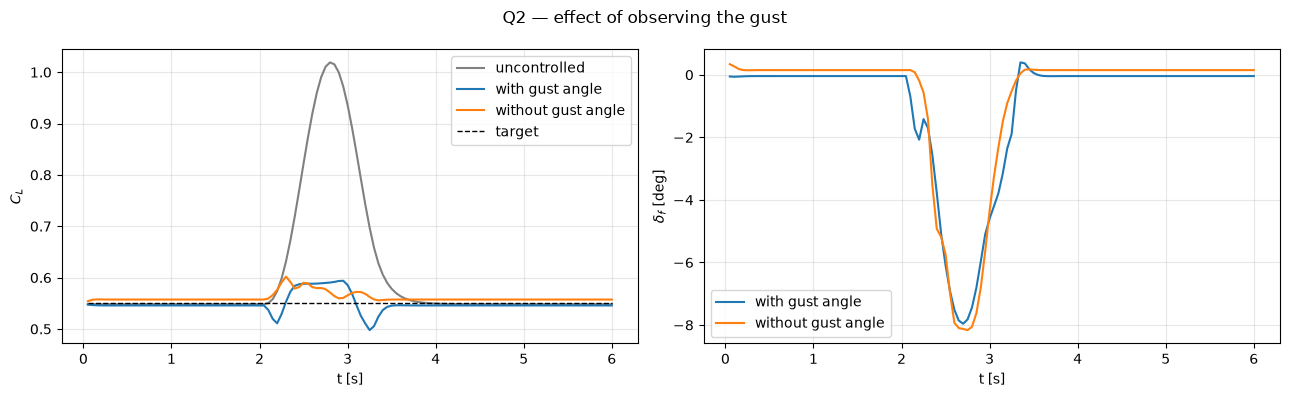

,configuration,"RMSE W0=+2.5,Tg=1.3","RMSE W0=-3.5,Tg=1.0","RMSE W0=-2.0,Tg=1.7","RMSE W0=+2.0,Tg=1.1","RMSE W0=+3.5,Tg=1.6",mean_RMSE,max_abs_flap_deg,mean_abs_flap_deg,mean_CD,action_roughness
0,"TD3 (main, Section 10)",0.01663,0.01282,0.02022,0.01540,0.01765,0.01654,12.05247,1.01187,0.01960,0.00954
1,TD3 without gust angle,0.01401,0.01523,0.00839,0.01278,0.01902,0.01389,11.78233,1.08300,0.01996,0.00943


In [23]:
class NoGustObservationEnv(AirfoilGymEnv):
    LOW, HIGH = np.array([-2.0, -2.0, -1.5], np.float32), np.array([2.0, 2.0, 1.5], np.float32)

    def __init__(self, **kw):
        super().__init__(**kw)
        self.observation_space = spaces.Box(low=self.LOW, high=self.HIGH, dtype=np.float32)

    def _get_obs(self):
        obs = np.array([self.cl / 1.5, self.cl_target / 1.5, self.flap_deg / self.max_flap_deg], dtype=np.float32)
        return np.clip(obs, self.LOW, self.HIGH)

check_env(NoGustObservationEnv(), warn=True)
no_gust_agent = train_agent(MODEL, f"q2_{MODEL.lower()}_no_gust_observation", NoGustObservationEnv(lift_model="linear", random_gust=True))
q2_table = pd.DataFrame([baseline_rows[1], suite_metrics(no_gust_agent, f"{MODEL} without gust angle", env_cls=NoGustObservationEnv)])
q2_table.to_csv(EX_DIR / "q2_no_gust_observation.csv", index=False)

tr_full = fly(model, 2.5, 1.3); tr_blind = fly(no_gust_agent, 2.5, 1.3, env_cls=NoGustObservationEnv)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(uncontrolled["time"], uncontrolled["cl"], color="gray", label="uncontrolled")
ax[0].plot(tr_full["time"], tr_full["cl"], label="with gust angle"); ax[0].plot(tr_blind["time"], tr_blind["cl"], label="without gust angle")
ax[0].plot(tr_full["time"], tr_full["cl_target"], "k--", lw=1, label="target"); ax[0].set_ylabel(r"$C_L$")
ax[1].plot(tr_full["time"], tr_full["flap_deg"], label="with gust angle"); ax[1].plot(tr_blind["time"], tr_blind["flap_deg"], label="without gust angle")
ax[1].set_ylabel(r"$\delta_f$ [deg]")
for a in ax: a.set_xlabel("t [s]"); a.grid(True, alpha=0.3); a.legend()
fig.suptitle("Q2 — effect of observing the gust"); fig.tight_layout(); fig.savefig(EX_DIR / "q2_no_gust_observation.png", dpi=120); plt.show()
q2_table.round(5)

## Q3 — Why penalise changes in action as well as magnitude? *(executed)*

We retrain with `smoothness_weight=0` (magnitude penalty kept). The rate penalty $\lambda_{\Delta a}(a_t-a_{t-1})^2$ discourages chattering commands that a real actuator could not follow and that would excite structural modes; the comparison shows what the agent does without it.

loading ../models/02_airfoil_gust_control_thin_airfoil/exercises/q3_td3_no_smoothness_penalty.zip


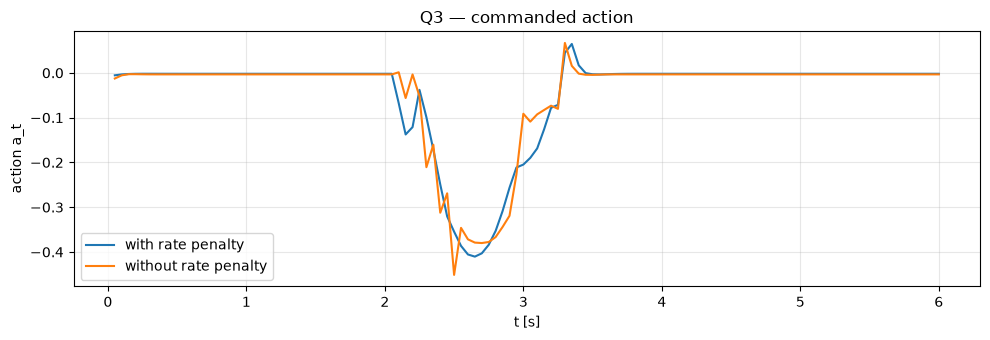

,configuration,"RMSE W0=+2.5,Tg=1.3","RMSE W0=-3.5,Tg=1.0","RMSE W0=-2.0,Tg=1.7","RMSE W0=+2.0,Tg=1.1","RMSE W0=+3.5,Tg=1.6",mean_RMSE,max_abs_flap_deg,mean_abs_flap_deg,mean_CD,action_roughness
0,"TD3 (main, Section 10)",0.01663,0.01282,0.02022,0.01540,0.01765,0.01654,12.05247,1.01187,0.01960,0.00954
1,TD3 with smoothness_weight=0,0.01549,0.01321,0.01604,0.01236,0.04004,0.01943,11.60923,0.97358,0.01966,0.01134


In [24]:
rough_agent = train_agent(MODEL, f"q3_{MODEL.lower()}_no_smoothness_penalty",
                          AirfoilGymEnv(lift_model="linear", random_gust=True, smoothness_weight=0.0))
q3_table = pd.DataFrame([baseline_rows[1], suite_metrics(rough_agent, f"{MODEL} with smoothness_weight=0")])
q3_table.to_csv(EX_DIR / "q3_smoothness_penalty.csv", index=False)
tr_r = fly(rough_agent, 2.5, 1.3)
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(tr_full["time"], tr_full["action"], label="with rate penalty"); ax.plot(tr_r["time"], tr_r["action"], label="without rate penalty")
ax.set_xlabel("t [s]"); ax.set_ylabel("action a_t"); ax.grid(True, alpha=0.3); ax.legend(); ax.set_title("Q3 — commanded action")
fig.tight_layout(); fig.savefig(EX_DIR / "q3_smoothness_penalty.png", dpi=120); plt.show()
q3_table.round(5)

## Q4 — What happens if the flap actuator becomes much slower? *(executed)*

The flap time constant is raised from $\tau_f=0.10$ s to $0.50$ s. First the **trained** policy is tested on the slow actuator without retraining (a model mismatch), then a new agent is trained on the slow actuator.

In [25]:
slow_agent = train_agent(MODEL, f"q4_{MODEL.lower()}_slow_flap", AirfoilGymEnv(lift_model="linear", random_gust=True, tau_flap=0.5))
q4_table = pd.DataFrame([
    {"actuator": "tau_f = 0.10 s", **suite_metrics(model, f"{MODEL} trained on fast flap")},
    {"actuator": "tau_f = 0.50 s", **suite_metrics(zero_policy, "uncontrolled", tau_flap=0.5)},
    {"actuator": "tau_f = 0.50 s", **suite_metrics(model, f"{MODEL} trained on fast flap (not retrained)", tau_flap=0.5)},
    {"actuator": "tau_f = 0.50 s", **suite_metrics(slow_agent, f"{MODEL} retrained on slow flap", tau_flap=0.5)},
])
q4_table.to_csv(EX_DIR / "q4_slow_flap.csv", index=False)
q4_table.round(5)

loading ../models/02_airfoil_gust_control_thin_airfoil/exercises/q4_td3_slow_flap.zip


,actuator,configuration,"RMSE W0=+2.5,Tg=1.3","RMSE W0=-3.5,Tg=1.0","RMSE W0=-2.0,Tg=1.7","RMSE W0=+2.0,Tg=1.1","RMSE W0=+3.5,Tg=1.6",mean_RMSE,max_abs_flap_deg,mean_abs_flap_deg,mean_CD,action_roughness
0,tau_f = 0.10 s,TD3 trained on fast flap,0.01663,0.01282,0.02022,0.01540,0.01765,0.01654,12.05247,1.01187,0.01960,0.00954
1,tau_f = 0.50 s,uncontrolled,0.13852,0.16576,0.13131,0.09985,0.21935,0.15096,0.00000,0.00000,0.02052,0.00000
2,tau_f = 0.50 s,TD3 trained on fast flap (not retrained),0.05105,0.06720,0.03708,0.04244,0.06632,0.05282,10.71878,0.97181,0.01976,0.01571
3,tau_f = 0.50 s,TD3 retrained on slow flap,0.02109,0.02187,0.01391,0.01516,0.02952,0.02031,10.71891,1.04796,0.01986,0.02562


## Q5 — Training gusts much weaker than evaluation gusts *(executed)*

An agent is trained with gust amplitudes in $[-0.75, 0.75]$ m/s (instead of $[-3, 3]$) and evaluated on the same suite, whose gusts reach $\pm3.5$ m/s. This is extrapolation in the disturbance: the states seen at evaluation were never visited during training.

In [26]:
weak_agent = train_agent(MODEL, f"q5_{MODEL.lower()}_weak_training_gusts",
                         AirfoilGymEnv(lift_model="linear", random_gust=True, gust_amplitude_range=(-0.75, 0.75)))
strong = [(-3.5, 1.0), (3.5, 1.6), (-5.0, 1.2), (5.0, 1.2)]
q5_table = pd.DataFrame([
    suite_metrics(model, f"{MODEL} trained on |W0|<=3", gusts=strong),
    suite_metrics(weak_agent, f"{MODEL} trained on |W0|<=0.75", gusts=strong),
    suite_metrics(weak_agent, f"{MODEL} trained on |W0|<=0.75 — weak gusts only", gusts=[(0.5, 1.3), (-0.5, 1.3)]),
])
q5_table.to_csv(EX_DIR / "q5_weak_training_gusts.csv", index=False)
q5_table.round(5)

loading ../models/02_airfoil_gust_control_thin_airfoil/exercises/q5_td3_weak_training_gusts.zip


,configuration,"RMSE W0=-3.5,Tg=1.0","RMSE W0=+3.5,Tg=1.6","RMSE W0=-5.0,Tg=1.2","RMSE W0=+5.0,Tg=1.2",mean_RMSE,max_abs_flap_deg,mean_abs_flap_deg,mean_CD,action_roughness,"RMSE W0=+0.5,Tg=1.3","RMSE W0=-0.5,Tg=1.3"
0,TD3 trained on |W0|<=3,0.01282,0.01765,0.01415,0.01313,0.01443,16.94782,1.49928,0.01984,0.01437,NaN,NaN
1,TD3 trained on |W0|<=0.75,0.01160,0.06288,0.02637,0.08693,0.04694,15.30808,1.28874,0.02023,0.01062,NaN,NaN
2,TD3 trained on |W0|<=0.75 — weak gusts only,NaN,NaN,NaN,NaN,0.00323,1.96344,0.23408,0.01958,0.00179,0.00263,0.00383


## Q6 — Would the optimal controller change if drag were weighted much more strongly? *(executed)*

`drag_weight` is raised from 0.02 to 1.0 (50×). In this model drag grows with $C_L^2$ and with $\delta_f^2$, so the agent now trades lift tracking against flap use and lift level.

In [27]:
drag_agent = train_agent(MODEL, f"q6_{MODEL.lower()}_drag_weight_1", AirfoilGymEnv(lift_model="linear", random_gust=True, drag_weight=1.0))
q6_table = pd.DataFrame([baseline_rows[1], suite_metrics(drag_agent, f"{MODEL} with drag_weight=1.0")])
q6_table.to_csv(EX_DIR / "q6_drag_weight.csv", index=False)
q6_table.round(5)

loading ../models/02_airfoil_gust_control_thin_airfoil/exercises/q6_td3_drag_weight_1.zip


,configuration,"RMSE W0=+2.5,Tg=1.3","RMSE W0=-3.5,Tg=1.0","RMSE W0=-2.0,Tg=1.7","RMSE W0=+2.0,Tg=1.1","RMSE W0=+3.5,Tg=1.6",mean_RMSE,max_abs_flap_deg,mean_abs_flap_deg,mean_CD,action_roughness
0,"TD3 (main, Section 10)",0.01663,0.01282,0.02022,0.01540,0.01765,0.01654,12.05247,1.01187,0.01960,0.00954
1,TD3 with drag_weight=1.0,0.02787,0.02271,0.02629,0.02691,0.03101,0.02696,11.84482,1.24491,0.01922,0.01186


## Q7 — Which parts would remain unchanged if the aerodynamic model were replaced by OpenFOAM? *(executed check)*

The agent only ever sees the Gymnasium interface. The cell below prints that interface: it is all that the algorithm depends on. Replacing the physics inside `step()` (the lift lag, the $2\pi\alpha$ law and the drag polar) with a call to a CFD solver leaves the spaces, the reward definition, the Monitor, the SB3 algorithm and the evaluation code unchanged; what changes is the cost per step, the need for time-step and mesh settings inside the solver, and possibly the noise in the observed coefficients.

In [28]:
print("Observation space:", model.observation_space)
print("Action space:     ", model.action_space)
print("Policy network:   ", model.policy.__class__.__name__)
print("Environment methods the algorithm calls: reset(), step(); everything else is internal to the environment.")

Observation space: Box([-2.  -2.  -2.  -1.5], [2.  2.  2.  1.5], (4,), float32)
Action space:      Box(-1.0, 1.0, (1,), float32)
Policy network:    TD3Policy
Environment methods the algorithm calls: reset(), step(); everything else is internal to the environment.


## Extension — nonlinear lift curve (Section 15) *(executed)*

The policy trained on the linear law is tested in the `lift_model="nonlinear"` environment, then a new agent is trained on the nonlinear law. Larger gusts are added to the suite here, because the saturation only matters at large effective angles.

In [29]:
nl_agent = train_agent(MODEL, f"ext_{MODEL.lower()}_nonlinear_lift", AirfoilGymEnv(lift_model="nonlinear", random_gust=True))
nl_gusts = SUITE + [(6.0, 1.2), (-6.0, 1.2)]
ext_table = pd.DataFrame([
    suite_metrics(zero_policy, "uncontrolled (nonlinear)", gusts=nl_gusts, lift_model="nonlinear"),
    suite_metrics(model, f"{MODEL} trained linear, tested nonlinear", gusts=nl_gusts, lift_model="nonlinear"),
    suite_metrics(nl_agent, f"{MODEL} trained nonlinear, tested nonlinear", gusts=nl_gusts, lift_model="nonlinear"),
])
ext_table.to_csv(EX_DIR / "ext_nonlinear_lift.csv", index=False)
ext_table.round(5)

loading ../models/02_airfoil_gust_control_thin_airfoil/exercises/ext_td3_nonlinear_lift.zip


,configuration,"RMSE W0=+2.5,Tg=1.3","RMSE W0=-3.5,Tg=1.0","RMSE W0=-2.0,Tg=1.7","RMSE W0=+2.0,Tg=1.1","RMSE W0=+3.5,Tg=1.6","RMSE W0=+6.0,Tg=1.2","RMSE W0=-6.0,Tg=1.2",mean_RMSE,max_abs_flap_deg,mean_abs_flap_deg,mean_CD,action_roughness
0,uncontrolled (nonlinear),0.09440,0.16986,0.13643,0.07066,0.14095,0.17441,0.31124,0.15685,0.00000,0.00000,0.01943,0.00000
1,"TD3 trained linear, tested nonlinear",0.02084,0.02348,0.02903,0.02107,0.02043,0.02081,0.03112,0.02382,18.88444,1.44016,0.01935,0.01248
2,"TD3 trained nonlinear, tested nonlinear",0.01904,0.02365,0.03415,0.01873,0.02097,0.03325,0.04724,0.02815,17.01686,1.48531,0.01956,0.01721


In [30]:
# ================================================================
# INDEX OF SAVED OUTPUTS
# ================================================================
for p in sorted(EX_DIR.iterdir()):
    print(p)
for p in sorted(Path("../models/02_airfoil_gust_control_thin_airfoil").rglob("*.zip")):
    print(p)

../results/02_airfoil_gust_control_thin_airfoil/ext_nonlinear_lift.csv
../results/02_airfoil_gust_control_thin_airfoil/q1_algorithm_comparison.csv
../results/02_airfoil_gust_control_thin_airfoil/q2_no_gust_observation.csv
../results/02_airfoil_gust_control_thin_airfoil/q2_no_gust_observation.png
../results/02_airfoil_gust_control_thin_airfoil/q3_smoothness_penalty.csv
../results/02_airfoil_gust_control_thin_airfoil/q3_smoothness_penalty.png
../results/02_airfoil_gust_control_thin_airfoil/q4_slow_flap.csv
../results/02_airfoil_gust_control_thin_airfoil/q5_weak_training_gusts.csv
../results/02_airfoil_gust_control_thin_airfoil/q6_drag_weight.csv
../models/02_airfoil_gust_control_thin_airfoil/airfoil_0d_td3_final.zip
../models/02_airfoil_gust_control_thin_airfoil/exercises/ext_td3_nonlinear_lift.zip
../models/02_airfoil_gust_control_thin_airfoil/exercises/q1_ppo.zip
../models/02_airfoil_gust_control_thin_airfoil/exercises/q1_sac.zip
../models/02_airfoil_gust_control_thin_airfoil/exercises

# Appendix — written answers and findings

These cells are appended at the end so that the numbering of all executed cells is unchanged.

## Animation analysis — answers


- **A1** — The policy beats the uncontrolled lift RMSE (0.1385) at the first snapshot (step 1,000) and is within 10 % of its final RMSE (0.0163) by step 3,000. Learning on this low-order model is fast; the remaining 47,000 steps do not improve the fixed-gust RMSE further.
- **A2** — The flap moves at the gust onset ($t=2.10$ s), before the uncontrolled lift error exceeds 0.01 ($t=2.20$ s): the agent uses the observed gust angle to act *before* the lift error builds up (feedforward).
- **A3** — At the gust peak the flap has moved −7.82° against a gust angle of +4.76°, a ratio of −1.64. Pure cancellation of the angle change would need $-1/k_f=-1.82$, so the flap offsets about 90 % of the gust angle at that instant.

## Summary of the executed experiments

| Question | Finding (one seed per configuration; mean lift RMSE over the 5-gust suite, uncontrolled 0.151) |
|---|---|
| Q1 algorithms | PPO 0.0083, TD3 (main) 0.0165, SAC 0.0257 — all far below uncontrolled; differences between algorithms are within what one seed can show. |
| Q2 no gust angle | 0.0139 — no degradation in this run; feedback from the measured lift was sufficient for these gusts. |
| Q3 no rate penalty | Commands rougher (0.0113 vs 0.0095) and error not better (0.0194). |
| Q4 slow flap ($\tau_f$ 0.5 s) | Untrained policy: 0.0528 (3× worse); retrained: 0.0203. |
| Q5 weak training gusts | On strong gusts: 0.0469 vs 0.0144 for the policy trained on the full range — extrapolation in the disturbance fails. |
| Q6 drag weight 1.0 | Mean $C_D$ 0.0192 vs 0.0196, at the price of a larger lift error (0.0270). |
| Q7 | The algorithm only sees the observation/action spaces and `reset()`/`step()`; everything aerodynamic is inside the environment. |
| Nonlinear lift | Linear-trained policy transfers well to the saturating lift law (0.0238); retraining on it gave 0.0282 (single seed). |